In [10]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, 
                             roc_auc_score, roc_curve, precision_recall_curve)

from utils import fetch_df

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [11]:
query_ml = """
SELECT
    c.client_id,
    c.age,
    c.segment,
    c.status,
    count(DISTINCT t.tx_id) AS tx_count,
    coalesce(sum(t.amount), 0) AS total_gmv,
    coalesce(avg(t.amount), 0) AS avg_tx_amount,
    -- Сколько дней прошло с последней транзакции до конца года (31 дек 2024)
    dateDiff('day', max(t.tx_date), toDate('2024-12-31')) AS days_since_last_tx
FROM neobank_staging.stg_clients c
LEFT JOIN neobank_staging.stg_transactions t 
    ON c.client_id = t.client_id AND t.status = 'completed'
GROUP BY c.client_id, c.age, c.segment, c.status
"""
df = fetch_df(query_ml)
print(f"Загружено {len(df)} клиентов")
df.head()

Загружено 50000 клиентов


,client_id,age,segment,status,tx_count,total_gmv,avg_tx_amount,days_since_last_tx
0,25842,20,young,churned,4,21494.0,5373.500000,100
1,44408,23,young,active,15,78148.0,5209.866667,2
2,2527,35,family,churned,0,0.0,0.000000,<NA>
3,48901,29,family,churned,5,14290.0,2858.000000,3
4,44970,45,family,churned,7,37769.0,5395.571429,7


In [12]:
# 1. Делаем таргет (целевую переменную)
# 1 - ушел (churned), 0 - активен (active или blocked)
df["is_churned"] = (df["status"] == "churned").astype(int)

# 2. Обрабатываем категориальные признаки (One-Hot Encoding)
df = pd.get_dummies(df, columns=["segment"], drop_first=True)

# 3. Выбираем фичи (X) динамически: все числовые колонки, кроме ID и таргета
features = [
    col for col in df.columns 
    if col not in ["client_id", "status", "is_churned"] 
    and df[col].dtype in ['int64', 'float64', 'uint8', 'bool', 'int32']
]

X = df[features]
y = df["is_churned"]

print(f"Используемые признаки: {features}")
print("\nРаспределение классов:")
print(y.value_counts(normalize=True).round(3))

Используемые признаки: ['total_gmv', 'avg_tx_amount']

Распределение классов:
is_churned
1    0.835
0    0.165
Name: proportion, dtype: float64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабируем числовые признаки (важно для логистической регрессии)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
# Обучаем модель Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=7, random_state=42, class_weight="balanced")
rf_model.fit(X_train, y_train)

# Делаем предсказания
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1] # Вероятность оттока

In [15]:
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.19      0.82      0.31      1649
           1       0.90      0.31      0.46      8351

    accuracy                           0.40     10000
   macro avg       0.54      0.57      0.39     10000
weighted avg       0.78      0.40      0.44     10000

ROC-AUC Score: 0.5719


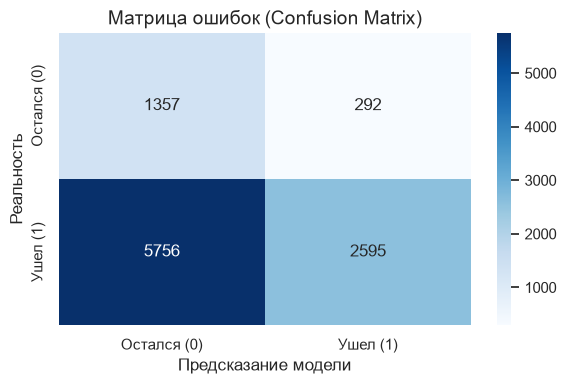

In [16]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Остался (0)", "Ушел (1)"], 
            yticklabels=["Остался (0)", "Ушел (1)"])
plt.title("Матрица ошибок (Confusion Matrix)", fontsize=14)
plt.ylabel("Реальность")
plt.xlabel("Предсказание модели")
plt.tight_layout()
plt.show()

C:\Users\Dima\AppData\Local\Temp\ipykernel_13728\3459815163.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=np.array(features)[indices], palette="viridis")


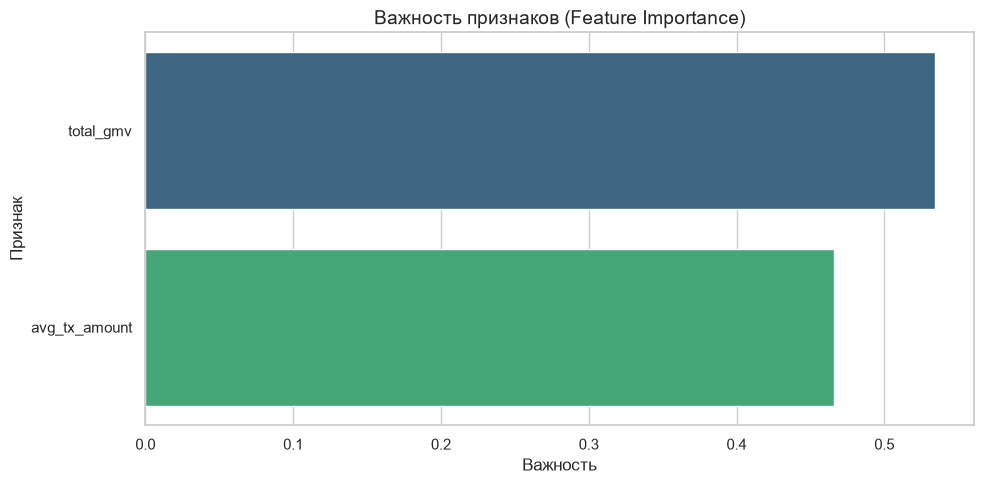

In [17]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=np.array(features)[indices], palette="viridis")
plt.title("Важность признаков (Feature Importance)", fontsize=14)
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

## 📊 Вывод по ML-модели Churn

**Бизнес-вопрос:** Кто из клиентов уйдет в ближайшее время?

**Метрики:**
* **ROC-AUC:** (вставь значение из Ячейки 6). Значение > 0.7 — хорошо, > 0.8 — отлично.
* **Recall (для класса 1):** Какую долю уходящих мы поймали? (См. Classification Report).
* **Precision (для класса 1):** Если мы говорим «он уйдет», насколько часто мы правы?

**Бизнес-эффект:**
Модель позволяет нам найти «тихих уходящих» клиентов (которые перестали тратить). Мы можем запустить для них email-кампанию с кэшбэком.
*Например, если модель ловит 70% уходящих, и мы удержим половину из них с помощью бонуса, мы сэкономим миллионы рублей LTV.*

**Главный инсайт (Feature Importance):**
Самый важный признак — **Days Since Last Tx** (или тот, что на первом месте на графике). Это значит, что если клиент не тратил деньги 60+ дней, он с высокой вероятностью уйдёт. 
**Рекомендация:** Настроить триггерное push-уведомление на 45-й день бездействия.